In [1]:
import cv2 
import os
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import string
#for building the model
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import models,layers
from keras.utils import to_categorical

In [2]:
import warnings
# Ignore all warnings
warnings.filterwarnings('ignore')

In [3]:
df='./dataset/TrainingSet'

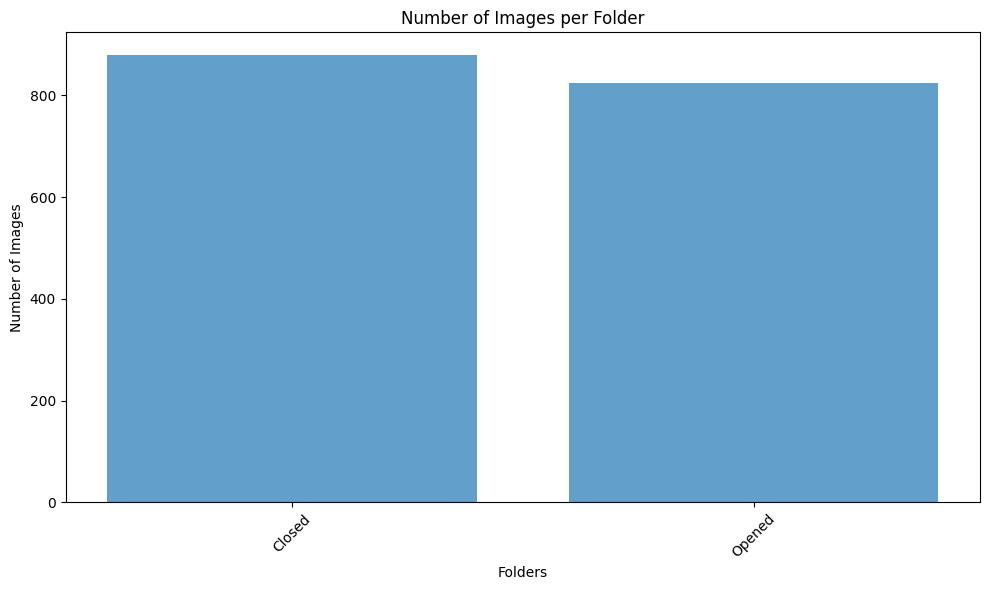

In [4]:
# Directory containing folders with images
root_dir = './dataset/TrainingSet'
#
# Dictionary to store counts for each folder
folder_counts = {}

# Iterate through each folder in the root directory
for folder in os.listdir(root_dir):
    folder_path = os.path.join(root_dir, folder)
    # Check if the item is a directory
    if os.path.isdir(folder_path):
        # Count the number of image files in the folder
        num_images = len([name for name in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, name)) and name.lower().endswith(('.png', '.jpg', '.jpeg'))])
        folder_counts[folder] = num_images

# Extract folder names and corresponding counts
folders = list(folder_counts.keys())
counts = list(folder_counts.values())

# Plotting the bar graph
plt.figure(figsize=(10, 6))
plt.bar(range(len(folders)), counts, align='center', alpha=0.7)
plt.xticks(range(len(folders)), folders, rotation=45)
plt.xlabel('Folders')
plt.ylabel('Number of Images')
plt.title('Number of Images per Folder')
plt.tight_layout()
plt.show()

In [5]:
Closed = os.listdir(os.path.join(df, "Closed"))
Opened = os.listdir(os.path.join(df, "Opened"))

print("Jumlah gambar Closed:", len(Closed))
print("Jumlah gambar Opened:", len(Opened))

Jumlah gambar Closed: 880
Jumlah gambar Opened: 824


In [6]:
X=[] #holding data
Y=[] #label

In [7]:
#Resizing and turning the images in Closed into numpy method
for i, image_name in enumerate(Opened):
    file_path = os.path.join(df, "Opened", image_name)
    image = Image.open(file_path)
    image = image.resize((64, 64), resample=Image.BOX)
    X.append(np.array(image))
    Y.append(0)

In [8]:
#Resizing and turning the images in Closed into numpy method
for i, image_name in enumerate(Closed):
    file_path = os.path.join(df, "Closed", image_name)
    image = Image.open(file_path)
    image = image.resize((64, 64), resample=Image.BOX)
    X.append(np.array(image))
    Y.append(1)

In [9]:
labels=np.unique(Y)
print(labels)

[0 1]


In [10]:
X[1]

array([[[98, 98, 98],
        [98, 98, 98],
        [98, 98, 98],
        ...,
        [98, 98, 98],
        [98, 98, 98],
        [98, 98, 98]],

       [[98, 98, 98],
        [98, 98, 98],
        [98, 98, 98],
        ...,
        [98, 98, 98],
        [98, 98, 98],
        [98, 98, 98]],

       [[98, 98, 98],
        [98, 98, 98],
        [98, 98, 98],
        ...,
        [98, 98, 98],
        [98, 98, 98],
        [98, 98, 98]],

       ...,

       [[98, 98, 98],
        [98, 98, 98],
        [98, 98, 98],
        ...,
        [98, 98, 98],
        [98, 98, 98],
        [98, 98, 98]],

       [[98, 98, 98],
        [98, 98, 98],
        [98, 98, 98],
        ...,
        [98, 98, 98],
        [98, 98, 98],
        [98, 98, 98]],

       [[98, 98, 98],
        [98, 98, 98],
        [98, 98, 98],
        ...,
        [98, 98, 98],
        [98, 98, 98],
        [98, 98, 98]]], dtype=uint8)

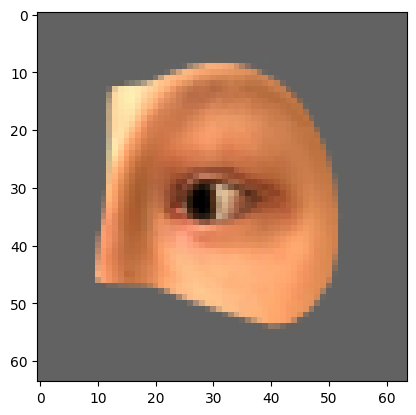

In [11]:
#X[5] is a NumPy array representing an image
image_array = X[5]

# Display the image
plt.imshow(image_array)
plt.show()

In [12]:

from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
import numpy as np

# Convert image data to NumPy arrays
X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.int32)

# Normalize pixel values from 0-255 to 0-1
X = X / 255.0

# Split into training and temporary test sets
x_train, x_temp, y_train_labels, y_temp = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y,
    shuffle=True
)

# Split temporary set into validation and test sets
x_val, x_test, y_val_labels, y_test_labels = train_test_split(
    x_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp,
    shuffle=True
)

# Convert labels to one-hot encoding
y_train = to_categorical(y_train_labels, num_classes=2)
y_val = to_categorical(y_val_labels, num_classes=2)
y_test = to_categorical(y_test_labels, num_classes=2)

print("X range:", X.min(), "to", X.max())
print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Testing:", x_test.shape, y_test.shape)
print("Class mapping: 0 = Opened, 1 = Closed")


X range: 0.0 to 1.0
Training: (1363, 64, 64, 3) (1363, 2)
Validation: (170, 64, 64, 3) (170, 2)
Testing: (171, 64, 64, 3) (171, 2)
Class mapping: 0 = Opened, 1 = Closed


In [13]:
#shape of x_test & y_test
#we will see the number of images will do testing(693) and the size(64,64) and the channels(RGB)
print(x_test.shape)
print(y_test.shape)

(171, 64, 64, 3)
(171, 2)


In [14]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten,
    Dense, Activation, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

num_classes = 2

model = Sequential([
    Conv2D(
        32, (3, 3), padding="same",
        input_shape=(64, 64, 3)
    ),
    Activation("relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(32, (3, 3), padding="same"),
    Activation("relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), padding="same"),
    Activation("relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(64, activation="relu"),
    Dropout(0.5),
    Dense(num_classes, activation="softmax")
])

model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

history = model.fit(
    x_train,
    y_train,
    batch_size=32,
    epochs=30,
    validation_data=(x_val, y_val),
    shuffle=True,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

model.save("Drowsiness_Detection_model_CNN.keras")


Epoch 1/30
43/43 [==============================] - 5s 75ms/step - loss: 0.6931 - accuracy: 0.5451 - val_loss: 0.6442 - val_accuracy: 0.9118 - lr: 0.0010
Epoch 2/30
43/43 [==============================] - 4s 88ms/step - loss: 0.4735 - accuracy: 0.8048 - val_loss: 0.2447 - val_accuracy: 0.9176 - lr: 0.0010
Epoch 3/30
43/43 [==============================] - 5s 117ms/step - loss: 0.2756 - accuracy: 0.8966 - val_loss: 0.2188 - val_accuracy: 0.9412 - lr: 0.0010
Epoch 4/30
43/43 [==============================] - 5s 118ms/step - loss: 0.2106 - accuracy: 0.9193 - val_loss: 0.1595 - val_accuracy: 0.9235 - lr: 0.0010
Epoch 5/30
43/43 [==============================] - 5s 122ms/step - loss: 0.1929 - accuracy: 0.9252 - val_loss: 0.1059 - val_accuracy: 0.9529 - lr: 0.0010
Epoch 6/30
43/43 [==============================] - 4s 102ms/step - loss: 0.1643 - accuracy: 0.9391 - val_loss: 0.1192 - val_accuracy: 0.9824 - lr: 0.0010
Epoch 7/30
43/43 [==============================] - 3s 80ms/step - loss:

In [15]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

y_pred = np.argmax(model.predict(x_test), axis=1)
y_true = y_test_labels

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Opened", "Closed"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nJumlah prediksi setiap kelas:")
print("Opened:", np.sum(y_pred == 0))
print("Closed:", np.sum(y_pred == 1))


6/6 [==============================] - 0s 18ms/step
Test Accuracy: 97.66%

Classification Report:
              precision    recall  f1-score   support

      Opened       0.99      0.96      0.98        83
      Closed       0.97      0.99      0.98        88

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171


Confusion Matrix:
[[80  3]
 [ 1 87]]

Jumlah prediksi setiap kelas:
Opened: 81
Closed: 90


In [16]:
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

# Print the model's performance
print(f'Test Loss: {loss:.4f}')
print(f'Test Accuracy: {accuracy*100:.2f}%')

Test Loss: 0.0869
Test Accuracy: 97.66%


In [17]:
from sklearn.metrics import classification_report, confusion_matrix

# Convert one-hot encoded y_test back to categorical labels
y_test_labels = np.argmax(y_test, axis=1)

# Get the model predictions on the test data
y_pred = np.argmax(model.predict(x_test), axis=1)

# Print the classification report
print("Classification Report:")
print(classification_report(y_test_labels, y_pred))

# Print the confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test_labels, y_pred))

6/6 [==============================] - 0s 16ms/step
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.96      0.98        83
           1       0.97      0.99      0.98        88

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171

Confusion Matrix:
[[80  3]
 [ 1 87]]


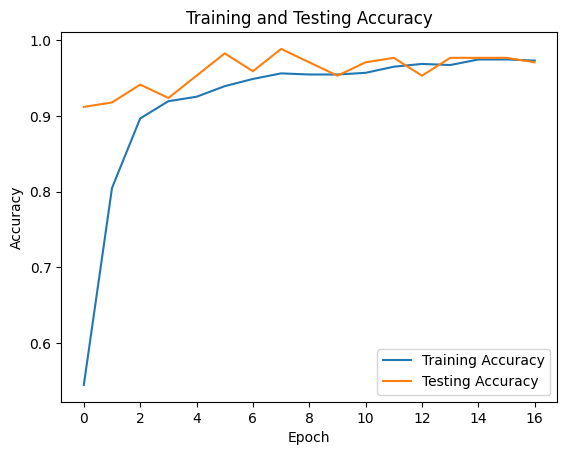

In [18]:
# Plotting training and testing accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Testing Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Testing Accuracy')
plt.legend()
plt.show()

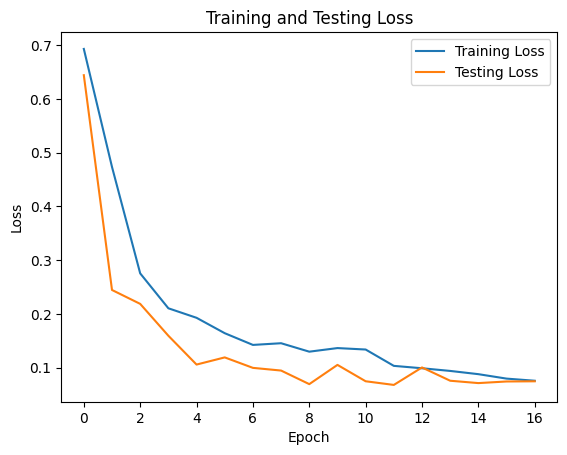

In [19]:
# Plot the training and testing loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Testing Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Testing Loss')
plt.legend()
plt.show()

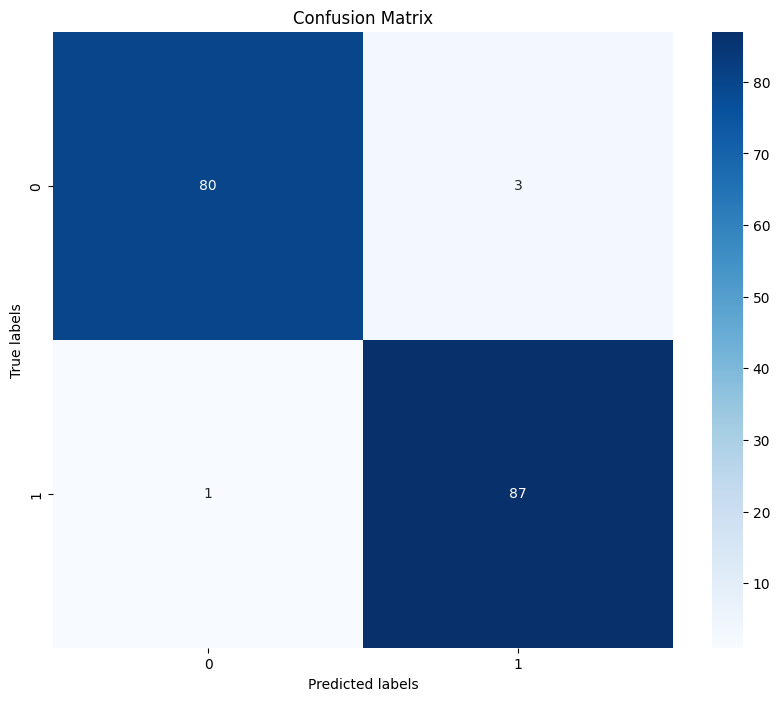

In [20]:
import seaborn as sns

# Compute confusion matrix
conf_matrix = confusion_matrix(y_test_labels, y_pred)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

6/6 [==============================] - 0s 21ms/step


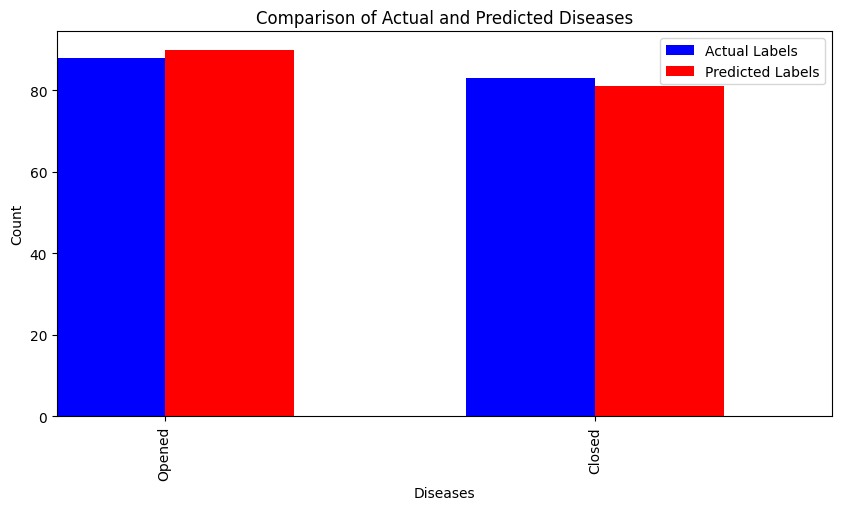

In [24]:
import pandas as pd

# Load the trained model
model = tf.keras.models.load_model('./Drowsiness_Detection_model_CNN.keras')

# Predict labels using the CNN model
predicted_probabilities = model.predict(x_test)
predicted_labels = np.argmax(predicted_probabilities, axis=1)

# Convert the NumPy array of predicted labels to a pandas Series
predicted_series = pd.Series(predicted_labels)

# Get value counts of actual labels
actual_counts = np.argmax(y_test, axis=1) 
actual_counts = pd.Series(actual_counts).value_counts()

# Get value counts of predicted labels
predicted_counts = predicted_series.value_counts()

# Create a bar plot
plt.figure(figsize=(10, 5))


# Define disease labels
disease_labels = ['Closed', 'Opened']

# Plot actual labels
actual_counts.index = [disease_labels[label] for label in actual_counts.index]
actual_counts.plot(kind='bar', color='blue', width=0.3, position=1, label='Actual Labels')

# Plot predicted labels
predicted_counts.index = [disease_labels[label] for label in predicted_counts.index]
predicted_counts.plot(kind='bar', color='red', width=0.3, position=0, label='Predicted Labels')

plt.xlabel('Diseases')
plt.ylabel('Count')
plt.title('Comparison of Actual and Predicted Diseases')
plt.legend()
plt.show()

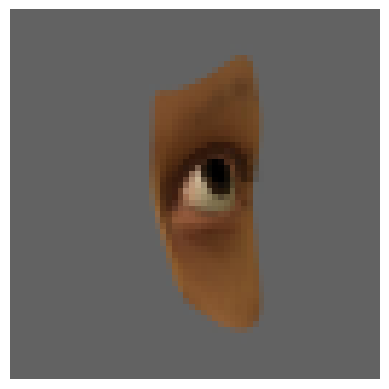

1/1 [==============================] - 0s 94ms/step
Actual class: Opened
Predicted class: Opened


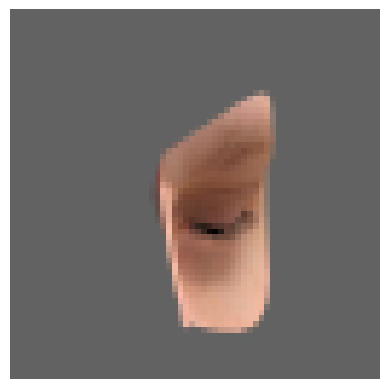

1/1 [==============================] - 0s 34ms/step
Actual class: Closed
Predicted class: Closed


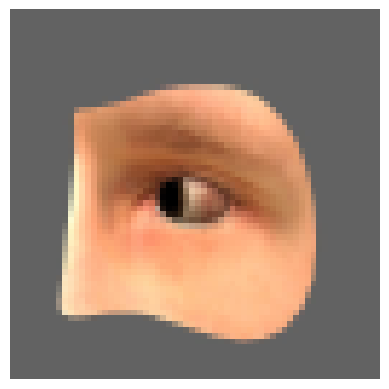

1/1 [==============================] - 0s 36ms/step
Actual class: Opened
Predicted class: Opened


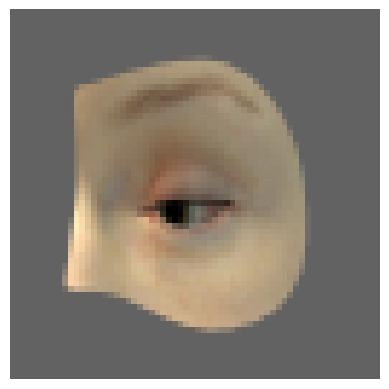

1/1 [==============================] - 0s 36ms/step
Actual class: Opened
Predicted class: Opened


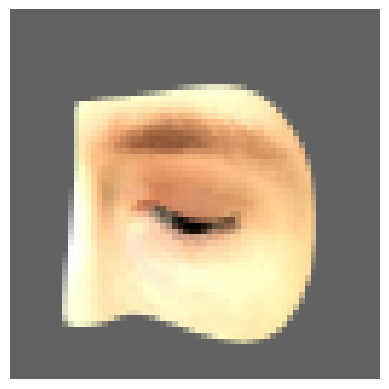

1/1 [==============================] - 0s 40ms/step
Actual class: Closed
Predicted class: Closed


In [25]:
model = tf.keras.models.load_model('./Drowsiness_Detection_model_CNN.keras')

# Assuming x_test and y_test are your test data
for i in range(5):
    # Get the ith image and its actual label
    current_image = x_test[i]
    actual_label = y_test[i]

    # Display the image
    plt.imshow(current_image)
    plt.axis('off')
    plt.show()

    # Get the model's prediction for the current image
    batch_prediction = model.predict(np.expand_dims(current_image, axis=0))
    predicted_label = np.argmax(batch_prediction)

    # Define disease labels
    disease_labels = ['Opened', 'Closed']

    # Map predicted label to class name
    predicted_class = disease_labels[predicted_label]

    # Map actual label to class name
    actual_class = disease_labels[np.argmax(actual_label)]
    
    # Print actual and predicted classes
    print("Actual class:", actual_class)
    print("Predicted class:", predicted_class)